In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



In [2]:
data = load_breast_cancer()

X = data.data
y = data.target


In [3]:
X_train,X_test,y_train, y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state =42,
    stratify =y
)

In [4]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
k_values = [1,3,5,7,9]
results =[]

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train,y_train)
    
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    
    results.append({
        'K':k,
        "Accuracy" : accuracy
    })
    
    

In [10]:
result_df = pd.DataFrame(results)
print(result_df)

   K  Accuracy
0  1  0.938596
1  3  0.982456
2  5  0.956140
3  7  0.973684
4  9  0.973684


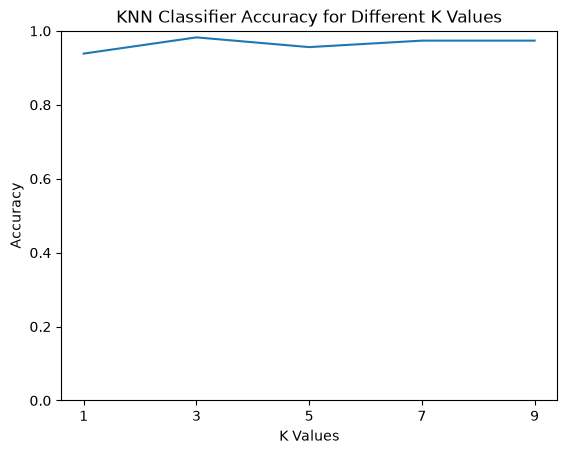

In [12]:
plt.title("KNN Classifier Accuracy for Different K Values")
plt.xlabel("K Values")
plt.ylabel("Accuracy")
plt.plot(result_df['K'].astype(str), result_df['Accuracy'])
plt.ylim(0,1)
plt.show()